<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 9: Decision-Tree Classifier and Rule Extraction</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.5 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Build a decision tree (ID3 from scratch on the Play-Tennis data and scikit-learn CART on the Iris data), interpret the learned rules and study overfitting with depth.</div>

## 📘 Theory

Entropy $H(S)=-\sum_k p_k\log_2p_k$; information gain $Gain(S,A)=H(S)-\sum_v\frac{|S_v|}{|S|}H(S_v)$.
ID3 chooses the attribute with the highest gain at each node and recurses until nodes are pure. CART uses the Gini index. Deep trees overfit; limit depth or prune.

## 🧭 Algorithm

1. Compute the entropy of the full dataset.
2. Compute the information gain of every attribute; split on the best.
3. Recurse on each subset until pure or no attributes remain.
4. Convert each root-to-leaf path into an IF–THEN rule; evaluate on test data.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
import pandas as pd
from math import log2
data = pd.DataFrame([
 ["Sunny","Hot","High","Weak","No"],["Sunny","Hot","High","Strong","No"],["Overcast","Hot","High","Weak","Yes"],
 ["Rain","Mild","High","Weak","Yes"],["Rain","Cool","Normal","Weak","Yes"],["Rain","Cool","Normal","Strong","No"],
 ["Overcast","Cool","Normal","Strong","Yes"],["Sunny","Mild","High","Weak","No"],["Sunny","Cool","Normal","Weak","Yes"],
 ["Rain","Mild","Normal","Weak","Yes"],["Sunny","Mild","Normal","Strong","Yes"],["Overcast","Mild","High","Strong","Yes"],
 ["Overcast","Hot","Normal","Weak","Yes"],["Rain","Mild","High","Strong","No"]],
 columns=["Outlook","Temperature","Humidity","Wind","Play"])
def H(s):
    p = s.value_counts(normalize=True); return -sum(q * log2(q) for q in p if q > 0)
def gain(df, a, t="Play"):
    return H(df[t]) - sum(len(g) / len(df) * H(g[t]) for _, g in df.groupby(a))
print(f"H(S) = {H(data['Play']):.3f}")
gains = {a: gain(data, a) for a in data.columns[:-1]}
for a, g in sorted(gains.items(), key=lambda x: -x[1]): print(f"  Gain(S, {a:<11}) = {g:.3f}")

H(S) = 0.940
  Gain(S, Outlook    ) = 0.247
  Gain(S, Humidity   ) = 0.152
  Gain(S, Wind       ) = 0.048
  Gain(S, Temperature) = 0.029


In [3]:
def id3(df, attrs, t="Play"):
    if df[t].nunique() == 1: return df[t].iloc[0]
    if not attrs: return df[t].mode()[0]
    best = max(attrs, key=lambda a: gain(df, a))
    return {best: {v: id3(g, [a for a in attrs if a != best]) for v, g in df.groupby(best)}}
tree = id3(data, list(data.columns[:-1]))
def rules(node, cond=()):
    if not isinstance(node, dict): yield cond, node; return
    (a, branches), = node.items()
    for v, sub in branches.items(): yield from rules(sub, cond + ((a, v),))
print("Learned tree:", tree, "\n")
for c, out in rules(tree): print("IF " + " AND ".join(f"{a} = {v}" for a, v in c) + f"  THEN Play = {out}")
def predict(node, x):
    while isinstance(node, dict): (a, br), = node.items(); node = br[x[a]]
    return node
acc = np.mean([predict(tree, r) == r["Play"] for _, r in data.iterrows()]); print(f"\nTraining accuracy: {acc:.0%}")

Learned tree: {'Outlook': {'Overcast': 'Yes', 'Rain': {'Wind': {'Strong': 'No', 'Weak': 'Yes'}}, 'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}}} 

IF Outlook = Overcast  THEN Play = Yes
IF Outlook = Rain AND Wind = Strong  THEN Play = No
IF Outlook = Rain AND Wind = Weak  THEN Play = Yes
IF Outlook = Sunny AND Humidity = High  THEN Play = No
IF Outlook = Sunny AND Humidity = Normal  THEN Play = Yes

Training accuracy: 100%


In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ks = sorted(gains, key=lambda k: -gains[k])
ax.bar(ks, [gains[k] for k in ks], color=[NAVY, TEAL, GOLD, CRIMSON])
for i, k in enumerate(ks): ax.text(i, gains[k] + 0.005, f"{gains[k]:.3f}", ha="center", color=NAVY, weight="bold")
ax.set_ylabel("information gain (bits)"); ax.set_title("Root selection: Outlook has the highest gain")
plt.tight_layout(); plt.savefig(f"{FIG}/exp09_gain.png", dpi=130); plt.show()

### scikit-learn CART on the Iris dataset

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
iris = load_iris(); X, y = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
clf = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)
print("Test accuracy:", round(accuracy_score(yte, clf.predict(Xte)), 3))
print("Confusion matrix:\n", confusion_matrix(yte, clf.predict(Xte)))
print("\nRules learned:\n" + export_text(clf, feature_names=list(iris.feature_names)))
plt.figure(figsize=(10, 5.5))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True, fontsize=9)
plt.title("CART decision tree (max_depth = 3)"); plt.savefig(f"{FIG}/exp09_iris_tree.png", dpi=130, bbox_inches="tight"); plt.show()

Test accuracy: 0.933
Confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]

Rules learned:
|--- petal width (cm) <= 0.70
|   |--- class: 0
|--- petal width (cm) >  0.70
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



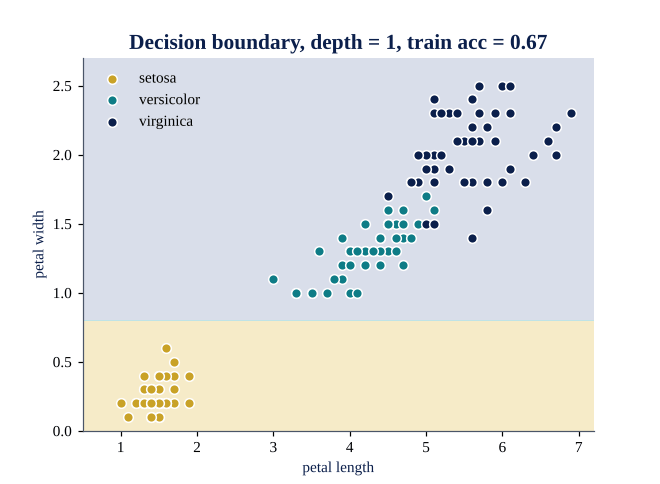

In [6]:
depths = range(1, 11); tr_acc, te_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr)
    tr_acc.append(m.score(Xtr, ytr)); te_acc.append(m.score(Xte, yte))
plt.figure(figsize=(6.5, 3.5)); plt.plot(depths, tr_acc, "-o", color=NAVY, label="train"); plt.plot(depths, te_acc, "-s", color=GOLD, label="test")
plt.xlabel("max depth"); plt.ylabel("accuracy"); plt.legend(frameon=False); plt.title("Depth vs accuracy — watch for overfitting")
plt.tight_layout(); plt.savefig(f"{FIG}/exp09_depth.png", dpi=130); plt.show()

X2 = X[:, 2:4]; xx, yy = np.meshgrid(np.linspace(0.5, 7.2, 300), np.linspace(0, 2.7, 300))
fig, ax = plt.subplots(figsize=(6, 4.4)); cm = matplotlib.colors.ListedColormap([GOLDL, "#BFE3E6", "#D9DEEA"])
def frm(k):
    d = k + 1; m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X2, y); ax.clear()
    ax.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), cmap=cm)
    for c, col in zip(range(3), [GOLD, TEAL, NAVY]): ax.scatter(*X2[y == c].T, color=col, edgecolor="white", s=40, label=iris.target_names[c])
    ax.set_xlabel("petal length"); ax.set_ylabel("petal width"); ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"Decision boundary, depth = {d}, train acc = {m.score(X2, y):.2f}")
gif = save_gif(animation.FuncAnimation(fig, frm, frames=6), "exp09_tree_boundary.gif", fps=1)
display(Image(filename=gif))

## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>ID3 selected Outlook (gain 0.247) as the root and produced five readable rules with 100% training accuracy. CART on Iris reached high test accuracy at depth 3; deeper trees fit training data perfectly without improving test accuracy — a sign of overfitting.</div>

## 🎤 Viva Questions

1. Define entropy and information gain.
2. Why is Outlook chosen as the root for Play Tennis?
3. Compare Gini index and entropy.
4. How does pruning reduce overfitting?
5. Why are decision trees considered interpretable models?